# Volatility analysis tool

Enter a ticker below and run all cells. Produces:
- Realized volatility across seven lookback windows (1 week to 1 year)
- An implied volatility smile chart across six expirations (1w, 2w, 1mo, 3mo, 6mo, 1yr),
  built from live options chain data
- A flag for any expiration whose window contains an upcoming earnings date


In [56]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import datetime
from IPython.display import HTML


## Set your ticker here

In [57]:
ticker = "SPY"  # <- change this and re-run the notebook


## Realized volatility

In [58]:
RV_WINDOWS = {
    "1wk": 5,
    "1mo": 21,
    "2mo": 42,
    "3mo": 63,
    "6mo": 126,
    "9mo": 189,
    "1yr": 252,
}

def compute_realized_vol(price_history: pd.DataFrame, windows: dict = RV_WINDOWS) -> pd.DataFrame:
    closes = price_history["Close"].dropna()
    log_returns = np.log(closes / closes.shift(1)).dropna()

    rows = []
    for label, n_days in windows.items():
        if len(log_returns) < n_days:
            rows.append({"window": label, "trading_days": n_days, "realized_vol_%": None})
            continue
        window_returns = log_returns.iloc[-n_days:]
        annualized = window_returns.std() * np.sqrt(252) * 100
        rows.append({"window": label, "trading_days": n_days, "realized_vol_%": round(annualized, 2)})
    return pd.DataFrame(rows)


In [59]:
t = yf.Ticker(ticker)

# Pull ~13 months so the 1-year (252 trading day) window has a full year of data behind it
price_history = t.history(period="13mo")

if price_history.empty:
    raise ValueError(f"No price history returned for '{ticker}' - check the ticker is valid.")

spot_price = price_history["Close"].iloc[-1]
rv_table = compute_realized_vol(price_history)

## Implied volatility data

In [60]:
def count_liquid_by_side(calls, puts, spot_price, low, high):
    def clean(df):
        d = df.copy()
        d["volume"] = d["volume"].fillna(0)
        d = d[d["volume"] > 0]
        d = d[(d["strike"] >= low) & (d["strike"] <= high)]
        return d
    calls_clean, puts_clean = clean(calls), clean(puts)
    n_calls = len(calls_clean[calls_clean["strike"] >= spot_price])
    n_puts = len(puts_clean[puts_clean["strike"] < spot_price])
    return n_calls, n_puts


def select_liquid_expirations(ticker_obj, spot_price, target_days, min_per_side=3, strike_band=(0.75, 1.25), max_candidates=6):
    all_expirations = ticker_obj.options
    if not all_expirations:
        raise ValueError(f"No options data available for {ticker_obj.ticker}.")

    today = datetime.today()
    parsed = [(exp, (datetime.strptime(exp, "%Y-%m-%d") - today).days) for exp in all_expirations]
    parsed = [p for p in parsed if p[1] > 0]
    low, high = spot_price * strike_band[0], spot_price * strike_band[1]

    chosen = {}
    used = set()
    chain_cache = {}
    skipped = []

    for label, target in target_days.items():
        candidates = sorted([p for p in parsed if p[0] not in used], key=lambda p: abs(p[1] - target))[:max_candidates]
        best_exp, best_score = None, -1
        for exp, days in candidates:
            if exp not in chain_cache:
                try:
                    chain_cache[exp] = ticker_obj.option_chain(exp)
                except Exception:
                    continue
            chain = chain_cache[exp]
            n_calls, n_puts = count_liquid_by_side(chain.calls, chain.puts, spot_price, low, high)
            score = min(n_calls, n_puts)
            if score > best_score:
                best_exp, best_score = exp, score
            if n_calls >= min_per_side and n_puts >= min_per_side:
                break
        if best_exp and best_score >= min_per_side:
            chosen[label] = best_exp
            used.add(best_exp)
        else:
            skipped.append(label)

    if skipped:
        print(f"Skipped (not enough liquid data on both sides): {', '.join(skipped)}")

    return chosen, chain_cache

In [61]:
def build_iv_grid(ticker_obj, spot_price, strike_band=(0.75, 1.25), near_atm_band_pct=0.06,
                  min_per_side=3, max_spread_ratio=0.50):
    target_days = {"1w": 7, "2w": 14, "1mo": 30, "3mo": 90, "6mo": 180, "1yr": 365}
    expiration_map, chain_cache = select_liquid_expirations(
        ticker_obj, spot_price, target_days, min_per_side=min_per_side
    )
    expirations = list(expiration_map.values())

    low, high = spot_price * strike_band[0], spot_price * strike_band[1]
    near_band = spot_price * near_atm_band_pct

    per_expiry = {}
    for exp in expirations:
        if exp in chain_cache:
            chain = chain_cache[exp]
        else:
            try:
                chain = ticker_obj.option_chain(exp)
            except Exception as e:
                print(f"Skipping {exp}: {e}")
                continue

        calls = chain.calls[["strike", "impliedVolatility", "volume", "openInterest", "bid", "ask"]].copy()
        puts = chain.puts[["strike", "impliedVolatility", "volume", "openInterest", "bid", "ask"]].copy()

        for df in (calls, puts):
            df["volume"] = df["volume"].fillna(0)
            df["openInterest"] = df["openInterest"].fillna(0)
            df["bid"] = df["bid"].fillna(0)
            df["ask"] = df["ask"].fillna(0)

        def clean(df):
            df = df.copy()
            # A contract with no bid has no market, whatever its open interest says
            df = df[df["bid"] > 0]
            # Require genuine two-sided interest, not just a stale mark
            df = df[(df["volume"] > 0) & (df["openInterest"] > 0)]
            # Drop quotes too wide to carry information
            mid = (df["bid"] + df["ask"]) / 2
            df = df[mid > 0]
            df = df[(df["ask"] - df["bid"]) / mid <= max_spread_ratio]
            df = df[(df["impliedVolatility"] > 0) & df["impliedVolatility"].notna()]
            return df

        calls_clean = clean(calls)
        puts_clean = clean(puts)

        near_calls = calls_clean[(calls_clean["strike"] >= spot_price - near_band) & (calls_clean["strike"] <= spot_price + near_band)]
        near_puts = puts_clean[(puts_clean["strike"] >= spot_price - near_band) & (puts_clean["strike"] <= spot_price + near_band)]

        offset = 0.0
        if len(near_calls) >= 2 and len(near_puts) >= 2:
            offset = near_calls["impliedVolatility"].mean() - near_puts["impliedVolatility"].mean()

        otm_puts = puts_clean[puts_clean["strike"] < spot_price].copy()
        otm_puts["impliedVolatility"] = otm_puts["impliedVolatility"] + offset
        otm_calls = calls_clean[calls_clean["strike"] >= spot_price]

        combined = pd.concat([otm_puts, otm_calls])
        combined = combined[(combined["strike"] >= low) & (combined["strike"] <= high)]

        if combined.empty:
            continue
        per_expiry[exp] = combined.groupby("strike")["impliedVolatility"].mean() * 100

    if not per_expiry:
        raise ValueError("No usable options data found - try widening strike_band.")

    grid = pd.DataFrame(per_expiry).sort_index()
    return grid.round(2)

In [62]:
iv_grid = build_iv_grid(t, spot_price)
iv_grid = iv_grid[sorted(iv_grid.columns, key=lambda d: datetime.strptime(d, "%Y-%m-%d"))]

## Earnings flag

In [63]:
def get_next_earnings_date(ticker_obj):
    try:
        edates = ticker_obj.get_earnings_dates(limit=8)
        if edates is None or edates.empty:
            return None
        future = edates[edates.index >= pd.Timestamp.now(tz=edates.index.tz)]
        if future.empty:
            return None
        return future.index.min().to_pydatetime()
    except Exception as e:
        print(f"Could not fetch earnings date: {e}")
        return None


def flag_expirations_with_earnings(expirations, next_earnings_date):
    if next_earnings_date is None:
        return {exp: False for exp in expirations}
    tz = next_earnings_date.tzinfo
    sorted_exps = sorted(expirations, key=lambda d: datetime.strptime(d, "%Y-%m-%d"))
    prev_date = datetime.now(tz) if tz else datetime.now()
    flags = {}
    for exp in sorted_exps:
        exp_date = datetime.strptime(exp, "%Y-%m-%d")
        if tz:
            exp_date = exp_date.replace(tzinfo=tz)
        flags[exp] = prev_date <= next_earnings_date <= exp_date
        prev_date = exp_date
    return flags


In [64]:
next_earnings = get_next_earnings_date(t)
earnings_flags = flag_expirations_with_earnings(list(iv_grid.columns), next_earnings)


SPY: No earnings dates found, symbol may be delisted


## IV smile across expirations

In [65]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.tab10.colors
for i, exp in enumerate(iv_grid.columns):
    series = iv_grid[exp].dropna()
    if len(series) < 4:
        continue
    color = colors[i % len(colors)]
    ax.plot(series.index, series.values, color=color, linewidth=1.6, marker="o",
            markersize=4, alpha=0.85, label=exp)

all_iv_values = iv_grid.values.flatten()
all_iv_values = all_iv_values[~np.isnan(all_iv_values)]
q1, q3 = np.percentile(all_iv_values, [25, 75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
non_outliers = all_iv_values[(all_iv_values >= lower_bound) & (all_iv_values <= upper_bound)]
if len(non_outliers) >= 2:
    axis_padding = (non_outliers.max() - non_outliers.min()) * 0.1
    ax.set_ylim(non_outliers.min() - axis_padding, non_outliers.max() + axis_padding)

ax.axvline(spot_price, color="black", linestyle="--", linewidth=1.2, alpha=0.7)
ylim = ax.get_ylim()
ax.text(spot_price, ylim[1], f" Spot: {spot_price:.2f}", va="top", ha="left", fontsize=9, color="black")

ax.set_xlabel("Strike")
ax.set_ylabel("Implied vol (%)")
ax.set_title(f"{ticker} IV smile across expirations")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()

import io, base64
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
plt.close(fig)
buf.seek(0)
smile_chart_b64 = base64.b64encode(buf.read()).decode("utf-8")

Window,Realized Vol (%)
1wk,8.73%
1mo,13.28%
2mo,12.42%
3mo,13.73%
6mo,14.13%
9mo,13.29%
1yr,12.85%

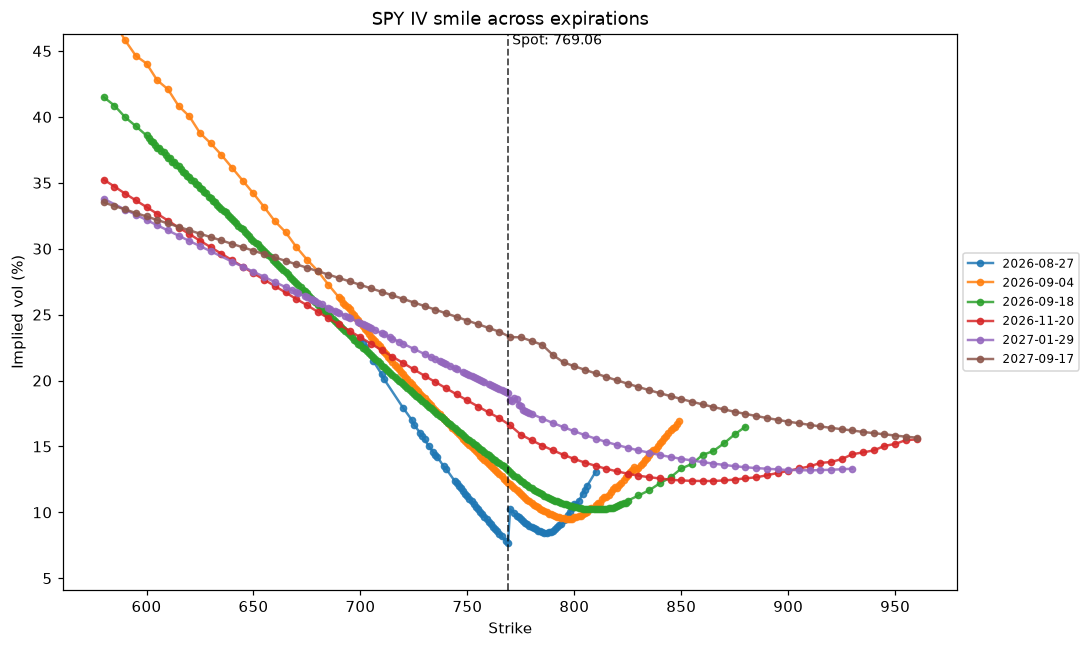

In [66]:
def render_summary(ticker, spot_price, rv_table, next_earnings_date, earnings_flags, chart_b64):
    display_table = rv_table[["window", "realized_vol_%"]].rename(
        columns={"window": "Window", "realized_vol_%": "Realized Vol (%)"}
    )

    styled = (
        display_table.style
        .hide(axis="index")
        .background_gradient(subset=["Realized Vol (%)"], cmap="Blues")
        .format({"Realized Vol (%)": "{:.2f}%"})
        .set_table_styles([
            {"selector": "th", "props": [("font-family", "sans-serif"), ("font-size", "13px"), ("text-align", "center"), ("padding", "8px 14px"), ("background-color", "#2b2b2b"), ("color", "white")]},
            {"selector": "td", "props": [("font-family", "sans-serif"), ("font-size", "13px"), ("text-align", "center"), ("padding", "6px 14px")]},
            {"selector": "table", "props": [("border-collapse", "collapse"), ("border-radius", "8px"), ("overflow", "hidden")]},
        ])
    )

    if next_earnings_date is None:
        earnings_line = "No upcoming earnings date found."
    else:
        earnings_line = f"Next earnings: <b>{next_earnings_date.date()}</b>"

    combined_html = f"""
    <div style="font-family: sans-serif;">
      <div style="margin-bottom: 10px;">
        <span style="font-size: 20px; font-weight: 700;">{ticker}</span>
        <span style="font-size: 16px; color: #555; margin-left: 10px;">Spot: {spot_price:.2f}</span>
      </div>
      <div style="display: flex; gap: 24px; align-items: flex-start;">
        <div style="flex: 0 0 auto;">
          <div style="font-size: 13px; color: #333; margin-bottom: 10px; padding: 8px 12px; background: #EAF2FB; border-left: 3px solid #2166AC; border-radius: 4px; max-width: 280px;">
            {earnings_line}
          </div>
          {styled.to_html()}
        </div>
        <div style="flex: 1 1 auto;">
          <img src="data:image/png;base64,{chart_b64}" style="max-width: 100%;">
        </div>
      </div>
    </div>
    """

    return HTML(combined_html)

render_summary(ticker, spot_price, rv_table, next_earnings, earnings_flags, smile_chart_b64)

## Notes

**Data source.** Prices and option chains are pulled live from Yahoo Finance, so output
reflects whatever the market looks like at the moment you run the notebook.

**Realized volatility.** Standard deviation of daily log returns over each window,
annualized by the square root of 252.

**Expiration selection.** Six targets are attempted (1w, 2w, 1mo, 3mo, 6mo, 1yr). For each,
the notebook picks the nearest expiration that has at least three contracts with volume on both
sides of spot. Any target that cannot be filled is skipped and printed by name, so an
illiquid underlying produces fewer than six curves.

**Contract filtering.** A quote is used only if it has a live bid, non-zero volume and open
interest, and a bid-ask spread under 50% of the mid. Only out-of-the-money contracts are
kept: puts below spot, calls at or above.

**Put/call offset.** Puts and calls near the money carry a systematic gap in quoted IV. The
notebook measures that gap within a 6% band around spot and shifts the put wing by it, so
the curve is continuous where the data switches from puts to calls.

**Plotting.** Each line connects the actual filtered quotes for one expiration. Nothing is
fitted or smoothed. The y-axis is bounded by the interquartile range of all quotes so a few
extreme readings do not compress the chart — axis scaling only, no data removed.

**Known limitation.** The strike band is a fixed 75–125% of spot, which spans a different
number of standard deviations at each expiration — short-dated curves reach much further
into the tails than long-dated ones. Plotting against delta instead of strike is the
standard fix and is the next version of this tool.